# 02 · k-means: distancia, K y puntos de partida
    **Objetivo.** Comparar cuatro conjuntos de features con y sin estandarizar.
    k-means acerca puntos a centroides y minimiza WCSS. ¿Cambiar las unidades
    cambia los grupos aunque los puntos sean los mismos?

**Nota de ejecución.** Celdas ejecutadas en orden con IPython dentro de `.venv`, porque nbconvert no pudo abrir los sockets del kernel en este sandbox. El usuario había verificado la versión previa con nbconvert fuera de esta restricción. Logs de esta revisión en `outputs/logs/`; auxiliares en `outputs/cache/`.

In [1]:
import os, sys, json, time, importlib.util
from pathlib import Path
sys.path.insert(0, "../../src")
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, voxel_ids, build_features
from pcseg.propagate import propagate_labels
from pcseg.metrics import cluster_summary, silhouette_sample, davies_bouldin, stability_ari
# Mostramos los PNG generados sin abrir ventanas gráficas.
plt.switch_backend("module://matplotlib_inline.backend_inline")
# Evitamos que muchos threads hagan más lento un problema pequeño.
thread_limit = threadpool_limits(limits=2)
OUT = Path('../../outputs'); FIG = OUT / 'figs'; ENT = Path('../../entregable'); ENT.mkdir(exist_ok=True)
CACHE = OUT / 'cache'; LOGS = OUT / 'logs'
for folder in (OUT, FIG, CACHE, LOGS): folder.mkdir(exist_ok=True)
(LOGS / 'clase_labels').mkdir(exist_ok=True)
START = time.perf_counter()
SEED = 0
print('Python:', sys.executable, sys.version.split()[0])
assert Path(sys.prefix).resolve() == Path('../../.venv').resolve(), 'Ejecutar con .venv'

Python: /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


### Cómo vamos a dibujar
Usamos una función local de matplotlib: puntos de tamaño 2–2.2 y alpha=0.6. La paleta prioriza colores contrastantes y es la misma en figuras y PLY. Esto cambia la presentación, no el clustering.

In [2]:
# Reordenamos tab20: primero los tonos fuertes; misma paleta en PNG y PLY.
SEGMENT_PALETTE = (np.array(plt.get_cmap('tab20').colors)[
    np.r_[np.arange(0,20,2), np.arange(1,20,2)]] * 255).astype(np.uint8)
def segment_rgb(labels):
    return labels_to_rgb(labels, palette=SEGMENT_PALETTE)

def scatter_views(points, values, path, title, max_points=40000, seed=0):
    # Variante local: puntos visibles y alpha=0.6, sin modificar pcseg.viz.
    if len(points) > max_points:
        idx = np.random.default_rng(seed).choice(len(points), max_points, replace=False)
        points, values = points[idx], values[idx]
    colors = (segment_rgb(values) if values.ndim == 1 else values) / 255.
    fig = plt.figure(figsize=(18,6))
    for j, (axis, label) in enumerate(((1,'y'),(2,'z')), start=1):
        ax = fig.add_subplot(1,3,j)
        ax.scatter(points[:,0],points[:,axis],c=colors,s=2.2,alpha=.6,linewidths=0)
        ax.set(xlabel='x',ylabel=label,title='Superior' if j==1 else 'Lateral',aspect='equal')
    ax = fig.add_subplot(1,3,3,projection='3d')
    ax.scatter(*points.T,c=colors,s=2,alpha=.6,linewidths=0)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D')
    ax.set_box_aspect(np.maximum(np.ptp(points,axis=0),1e-9))
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path,dpi=150); plt.close(fig)

### Recuperamos la misma muestra
No volvemos a sortear puntos: cargamos los índices guardados en 01.

In [3]:
cloud = read_ply('../../data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
sample_idx = np.load(OUT / 'sample_idx.npy')
assert len(np.unique(sample_idx)) == len(sample_idx)
xyz, rgb, normals = (cloud[key][sample_idx] for key in ('xyz', 'rgb', 'normals'))
print('Muestra común:', len(xyz), 'de', len(cloud['xyz']))

Muestra común: 93903 de 1647021


### Antes de comparar: fijemos la regla
Trabajamos siempre con los índices voxel de 01. `rgb` pasa a CIE Lab dentro de
`build_features`: aquí el nombre del conjunto indica el dato de origen.
`height = z - percentil_1(z)` repite la información de z y le da más peso a la altura.

Calculamos silhouette en 1200 puntos (semilla 0) y Davies-Bouldin sin ruido.
Silhouette mayor y DB menor son deseables, pero dependen de la distancia elegida.
Por eso guardamos además `silhouette_comun` y `DB_comun`, siempre sobre las mismas
features completas estandarizadas. No hay ground truth: ninguna métrica demuestra
que los grupos sean objetos físicos. ARI compara corridas, no exactitud.
Los segundos del CSV incluyen ajuste, predicción y estabilidad, y excluyen evaluación y figuras.

In [4]:
FEATURES = {
    'xyz': {},
    'xyz+rgb': {'use_rgb': True},
    'xyz+normales': {'use_normals': True},
    'xyz+rgb+normales+height': {'use_rgb': True, 'use_normals': True, 'use_height': True},
}
def features(name, scaled=True):
    return build_features(xyz, rgb, normals, standardize=scaled, **FEATURES[name])
# Evaluación común: igual distancia y mismas filas para comparar métodos/features.
EVAL = features('xyz+rgb+normales+height')

In [5]:
NB = '02'

rows = []
def record(method, feature, scaled, params, X, labels, seconds, ari, ari_std=0., **extra):
    summary = cluster_summary(labels)
    own_sil = silhouette_sample(X, labels, n=1200, seed=0)
    own_db = davies_bouldin(X, labels)
    common_sil = silhouette_sample(EVAL, labels, n=1200, seed=0)
    common_db = davies_bouldin(EVAL, labels)
    counts = np.array(list(summary['sizes'].values()), dtype=int)
    row_id = f'{NB}_{len(rows):03d}'
    row = dict(id=row_id, metodo=method, features=feature, estandarizado=bool(scaled),
        parametros=json.dumps(params, sort_keys=True), n_fit=extra.get("n_ajuste", len(X)), n_evaluacion=len(X),
        n_clusters=summary['n_clusters'], ruido=summary['noise_frac'],
        silhouette=own_sil, DB=own_db, ARI=ari, ARI_std=ari_std,
        silhouette_comun=common_sil, DB_comun=common_db, segundos=seconds,
        min_cluster_frac=float(counts.min()/len(labels)) if len(counts) else 0.,
        max_cluster_frac=float(counts.max()/len(labels)) if len(counts) else 0., **extra)
    rows.append(row)
    np.save(LOGS / 'clase_labels' / f'{row_id}.npy', labels.astype(np.int32))
    return row

def table():
    df = pd.DataFrame(rows)
    df.to_csv(OUT / f'metricas_{NB}.csv', index=False)
    return df

def view(labels, suffix, title):
    path = FIG / f'{NB}_{suffix}.png'
    scatter_views(xyz, labels, path, title, max_points=30000, seed=0)
    display(Image(filename=str(path)))

def finish(payload):
    payload['segundos_notebook'] = time.perf_counter() - START
    (CACHE / f'clase_resumen_{NB}.json').write_text(json.dumps(payload, indent=2))
    print(payload)

### Probamos K, sin decidir por una sola curva
Para cada representación ajustamos K=2…12 con tres starts (`n_init=3`). Repetimos el ajuste con semillas fijas 0, 1 y 2; `stability_ari` compara las tres parejas. Son excepciones deliberadas a la semilla principal 0 para medir sensibilidad. Guardamos cada configuración y las etiquetas de la corrida 0. WCSS solo se compara dentro de una misma representación.

In [6]:
from sklearn.cluster import KMeans
for name in FEATURES:
    for scaled in (False, True):
        X = features(name, scaled)
        for k in range(2, 13):
            tick = time.perf_counter()
            runs = {s: KMeans(n_clusters=k, n_init=3, max_iter=200, random_state=s).fit(X)
                    for s in (0, 1, 2)}
            ari, sd = stability_ari(lambda data, seed: runs[seed].labels_, X, [0,1,2])
            elapsed = time.perf_counter() - tick
            record('kmeans', name, scaled, {'n_clusters': k, 'n_init': 3, 'max_iter': 200},
                   X, runs[0].labels_, elapsed, ari, sd, WCSS=runs[0].inertia_)
        print(name, 'estandarizado =', scaled, 'listo', flush=True)
df = table()
display(df.sort_values('silhouette_comun', ascending=False).head(8))

xyz estandarizado = False listo


xyz estandarizado = True listo


xyz+rgb estandarizado = False listo


xyz+rgb estandarizado = True listo


xyz+normales estandarizado = False listo


xyz+normales estandarizado = True listo


xyz+rgb+normales+height estandarizado = False listo


xyz+rgb+normales+height estandarizado = True listo


,id,metodo,features,estandarizado,parametros,n_fit,n_evaluacion,n_clusters,ruido,silhouette,DB,ARI,ARI_std,silhouette_comun,DB_comun,segundos,min_cluster_frac,max_cluster_frac,WCSS
77,02_077,kmeans,xyz+rgb+normales+height,True,"{""max_iter"": 200, ""n_clusters"": 2, ""n_init"": 3}",93903,93903,2,0.0,0.261461,1.539746,0.999531,0.000332,0.261461,1.539746,0.130926,0.289277,0.710723,726292.566093
11,02_011,kmeans,xyz,True,"{""max_iter"": 200, ""n_clusters"": 2, ""n_init"": 3}",93903,93903,2,0.0,0.355876,1.162598,0.999182,0.000433,0.255352,1.595684,0.089662,0.295198,0.704802,189212.161601
55,02_055,kmeans,xyz+normales,True,"{""max_iter"": 200, ""n_clusters"": 2, ""n_init"": 3}",93903,93903,2,0.0,0.248697,1.749835,0.992873,0.002500,0.228284,1.846250,0.128250,0.396313,0.603687,436746.814671
56,02_056,kmeans,xyz+normales,True,"{""max_iter"": 200, ""n_clusters"": 3, ""n_init"": 3}",93903,93903,3,0.0,0.246547,1.736862,0.583433,0.291416,0.217094,2.067527,0.164569,0.268106,0.458271,370209.761039
78,02_078,kmeans,xyz+rgb+normales+height,True,"{""max_iter"": 200, ""n_clusters"": 3, ""n_init"": 3}",93903,93903,3,0.0,0.214459,1.892853,0.992690,0.004520,0.214459,1.892853,0.165573,0.277371,0.372555,631695.310835
82,02_082,kmeans,xyz+rgb+normales+height,True,"{""max_iter"": 200, ""n_clusters"": 7, ""n_init"": 3}",93903,93903,7,0.0,0.213644,1.663128,0.617075,0.057387,0.213644,1.663128,0.375467,0.025068,0.227437,490504.334304
86,02_086,kmeans,xyz+rgb+normales+height,True,"{""max_iter"": 200, ""n_clusters"": 11, ""n_init"": 3}",93903,93903,11,0.0,0.213259,1.510333,0.952452,0.032318,0.213259,1.510333,0.836872,0.022981,0.188482,402965.627330
85,02_085,kmeans,xyz+rgb+normales+height,True,"{""max_iter"": 200, ""n_clusters"": 10, ""n_init"": 3}",93903,93903,10,0.0,0.210343,1.532920,0.732065,0.044393,0.210343,1.532920,0.582138,0.023173,0.192220,420279.363926


### Elbow, silhouette y estabilidad
Elbow busca dónde la mejora de WCSS empieza a ser menor. Silhouette pregunta si cada punto está más cerca de su grupo que del vecino. ARI muestra si otros starts recuperan una partición parecida; una curva alta de silhouette puede venir con inestabilidad.

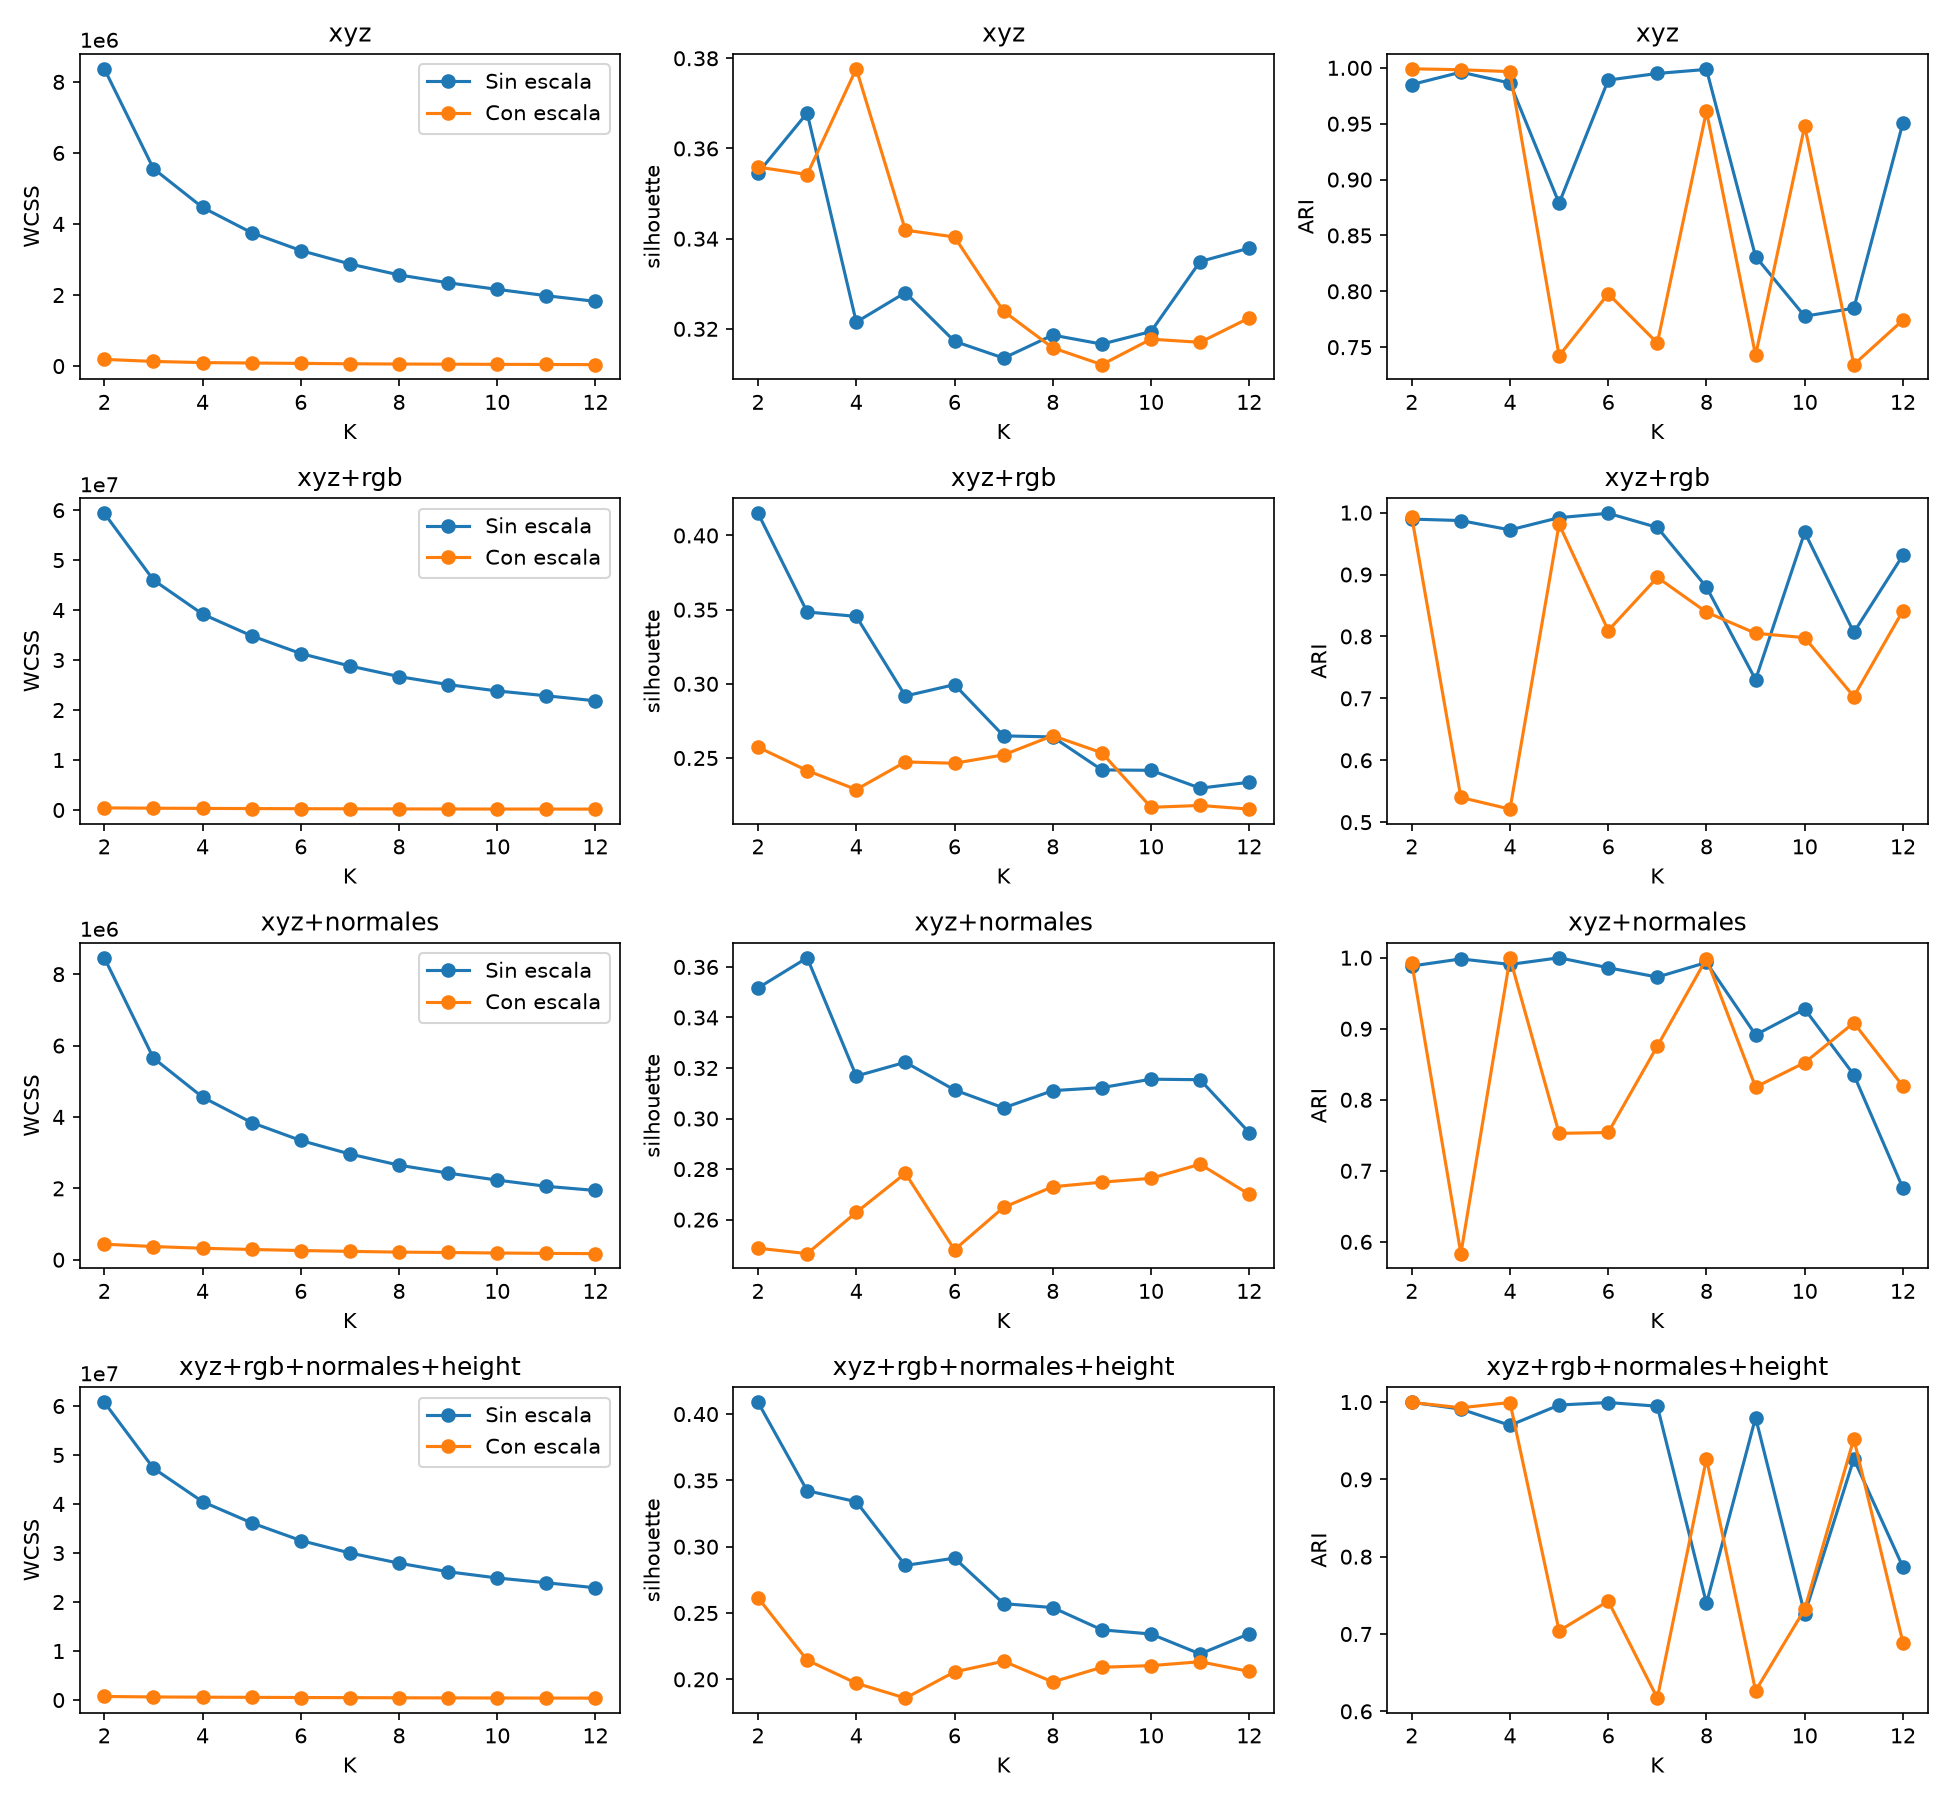

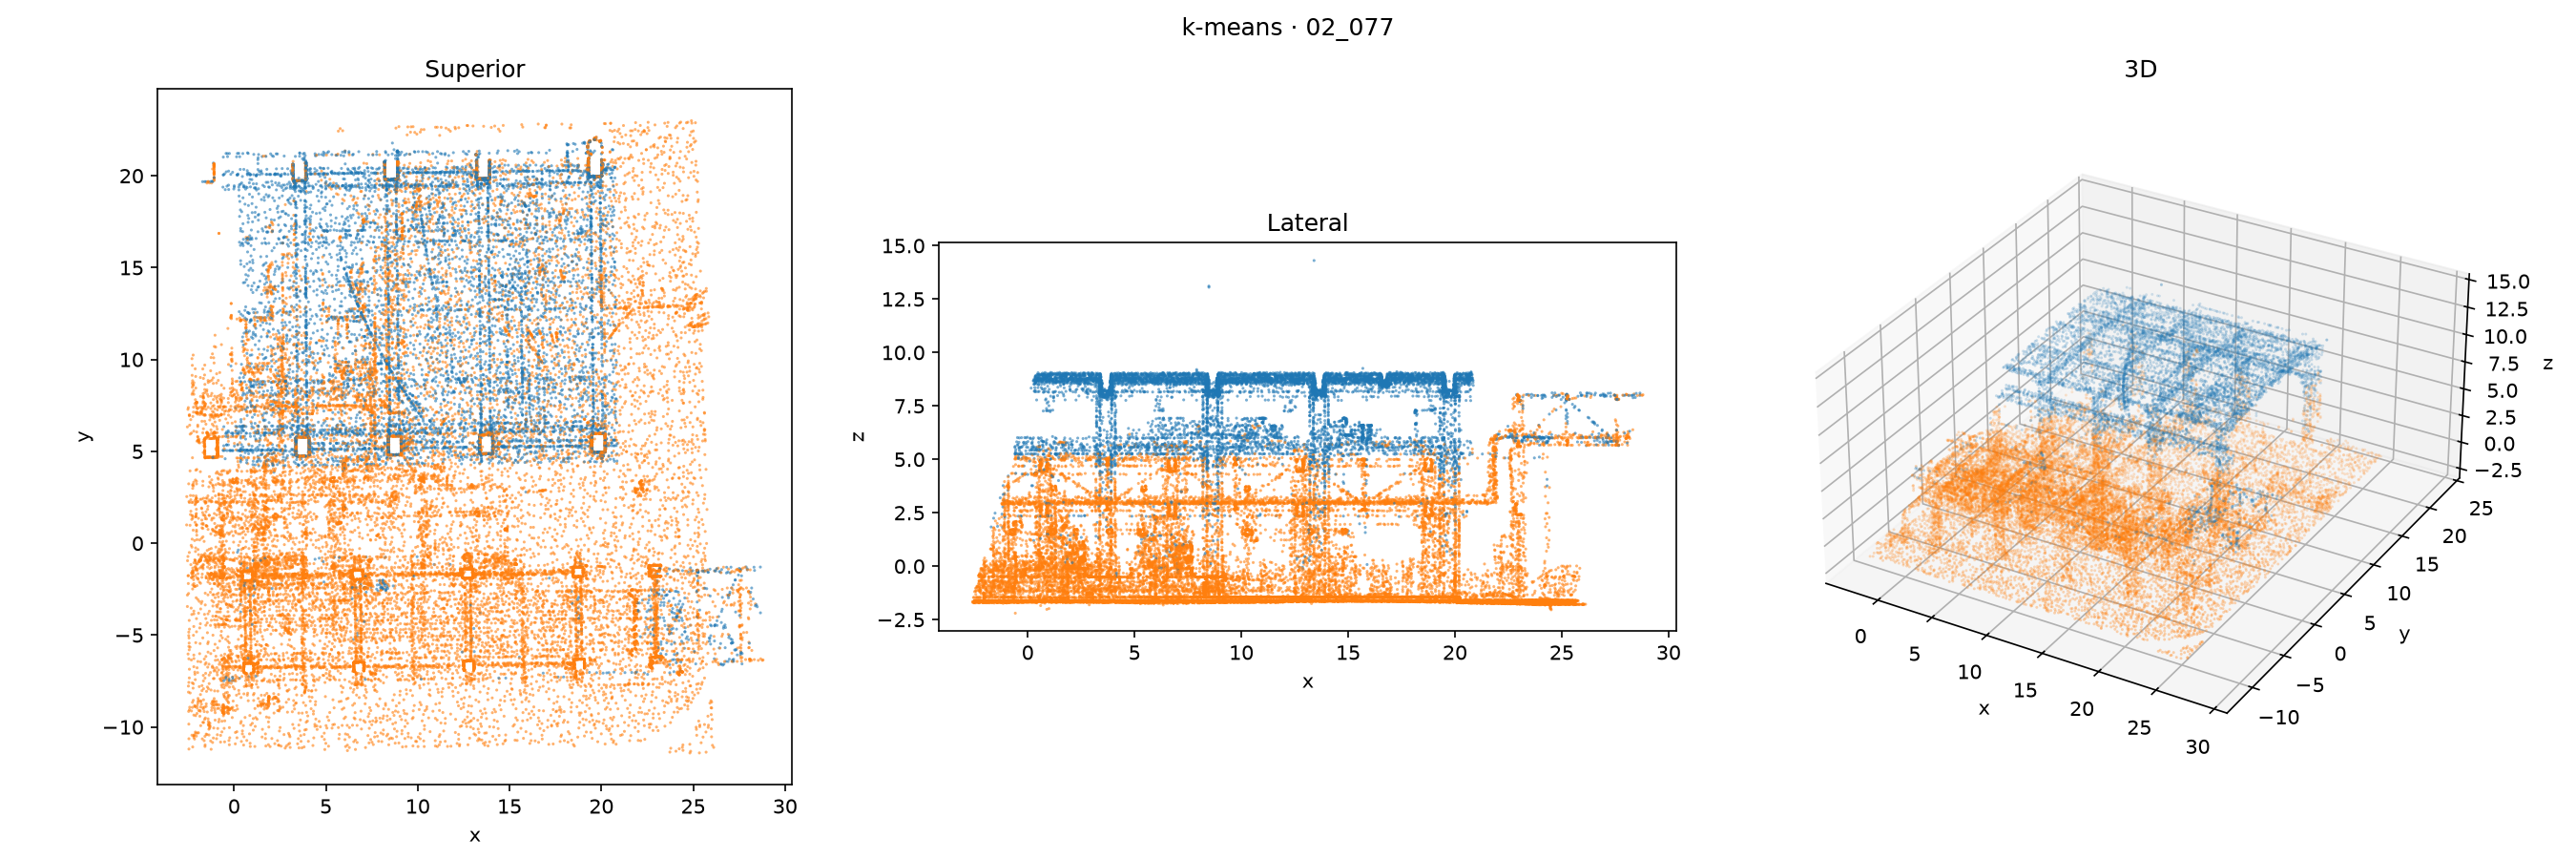

{'mejor': {'id': '02_077', 'metodo': 'kmeans', 'features': 'xyz+rgb+normales+height', 'estandarizado': True, 'parametros': '{"max_iter": 200, "n_clusters": 2, "n_init": 3}', 'n_fit': 93903, 'n_evaluacion': 93903, 'n_clusters': 2, 'ruido': 0.0, 'silhouette': 0.26146050643317625, 'DB': 1.5397462982407202, 'ARI': 0.9995309087665637, 'ARI_std': 0.00033169759215805, 'silhouette_comun': 0.26146050643317625, 'DB_comun': 1.5397462982407202, 'segundos': 0.1309264509982313, 'min_cluster_frac': 0.28927723288925805, 'max_cluster_frac': 0.7107227671107419, 'WCSS': 726292.5660929127}, 'ari_min': 0.521125572682771, 'ari_max': 0.9999023697237831, 'configuraciones': 88, 'segundos_notebook': 32.64666734699858}


In [7]:
fig, axes = plt.subplots(4, 3, figsize=(13, 12))
for i, name in enumerate(FEATURES):
    for scaled in (False, True):
        part = df[(df.features == name) & (df.estandarizado == scaled)]
        ks = [json.loads(p)['n_clusters'] for p in part.parametros]
        for j, metric in enumerate(['WCSS','silhouette','ARI']):
            axes[i,j].plot(ks, part[metric], 'o-', label='Con escala' if scaled else 'Sin escala')
            axes[i,j].set(xlabel='K', ylabel=metric, title=name)
    axes[i,0].legend()
fig.tight_layout(); fig.savefig(FIG / '02_curvas.png', dpi=150); display(Image(filename=str(FIG / '02_curvas.png'))); plt.close(fig)
best = df.sort_values(['silhouette_comun','DB_comun'], ascending=[False,True]).iloc[0]
view(np.load(LOGS / 'clase_labels' / f'{best.id}.npy'), 'mejor', f'k-means · {best.id}')
finish({'mejor': best.to_dict(), 'ari_min': float(df.ARI.min()),
        'ari_max': float(df.ARI.max()), 'configuraciones': len(df)})

## Qué aprendimos / qué falló

Probamos 88 configuraciones. Por silhouette común destacó 02_077 (xyz+rgb+normales+height, estandarizado=True, {"max_iter": 200, "n_clusters": 2, "n_init": 3}): silhouette común 0.261, DB común 1.540 y ARI 0.9995. El ARI entre starts varió de 0.521 a 1.000; por lo tanto, hay configuraciones más sensibles a la inicialización que otras. No podemos comparar WCSS de distintas escalas ni interpretar el mayor silhouette como segmentación semántica correcta.